# CIFAR-10 final training

## Purpose and workflow
This notebook takes the best recorded Optuna configuration, builds a fresh flexible CNN, trains it with Adam and cosine annealing, keeps a checkpoint selected by validation accuracy, plots the training history, and evaluates the selected model on CIFAR-10’s test split.

The recorded run uses a 90/10 stratified split of the original training data for training and validation. It trains for 50 epochs with batches of 128. The final section reports test loss, accuracy, precision, recall, and F1.

In [22]:
from data_preprocess import *
from help_utils import *
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
import optuna
import joblib
from pprint import pprint
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
from huggingface_hub import login
login()

In [ ]:
ds = get_data()

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

## Reproducible training and validation split

`get_train_and_eval_loaders` creates the split from `dataset['train']`, using a 10% validation share, `seed=42`, and `stratify_by_column='label'`. For CIFAR-10 this gives 45,000 training images and 5,000 validation images, with class proportions kept similar. The training loader shuffles batches; the validation loader does not. The official 10,000-image test split is loaded separately near the end.

The fixed split seed makes the membership of the train and validation subsets repeatable. The training loader’s batch order is still shuffled each run.

In [ ]:
def get_train_and_eval_loaders(dataset, batch_size=128):


    split = dataset['train'].train_test_split(test_size=0.1, seed=42,
                                              stratify_by_column="label",) # stratify_by_column="label" keeps class proportions similar in both subsets.

    train_ds = CIFAR_10(split['train'], TRANSFORM)
    valid_ds = CIFAR_10(split['test'], TRANSFORM)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False)

    return train_loader, val_loader

## Flexible CNN selected by Optuna

The model uses the best recorded Optuna architecture. It contains three convolutional blocks with 95, 111, and 44 output filters and 5×5 kernels. Each block applies convolution, ReLU, and 2×2 max pooling. The model dynamically builds its classifier from the resulting feature-map size, then applies dropout (0.1047), a 113-unit hidden layer, and a 10-class output layer.

A dummy 32×32 RGB image is passed through the model before Adam is created. This is required by the model’s dynamic classifier so the optimizer receives all model parameters.

In [ ]:
class FlexibleCNN(nn.Module):
    """
    A flexible Convolutional Neural Network with a dynamically created classifier.

    This CNN's architecture is defined by the provided hyperparameters,
    allowing for a variable number of convolutional layers. The classifier
    (fully connected layers) is constructed during the first forward pass
    to adapt to the output size of the convolutional feature extractor.
    """

    def __init__(self, n_layers, n_filters, kernel_sizes, dropout_rate, fc_size):
        """
        Initializes the feature extraction part of the CNN.

        Args:
            n_layers: The number of convolutional blocks to create.
            n_filters: A list of integers specifying the number of output
                       filters for each convolutional block.
            kernel_sizes: A list of integers specifying the kernel size for
                          each convolutional layer.
            dropout_rate: The dropout probability to be used in the classifier.
            fc_size: The number of neurons in the hidden fully connected layer.
        """
        super(FlexibleCNN, self).__init__()

        self.dropout_rate = dropout_rate
        self.fc_size = fc_size
        blocks = []
        in_channels = 3 # RGB input

        for i in range(n_layers):
            out_channels = n_filters[i]
            kernel_size = kernel_sizes[i]
            padding_size = (kernel_size - 1) // 2 # Same padding

            block = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding_size),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2)
            )

            blocks.append(block)
            in_channels = out_channels

        self.features = nn.Sequential(*blocks)

        # The classifier will be initialized dynamically in the forward pass
        self.classifier = None

    def _create_classifier(self, flattened_size, device):
        """
        Dynamically creates and initializes the classifier part of the network.

        This helper method is called during the first forward pass to build the
        fully connected layers based on the feature map size from the
        convolutional base.

        Args:
            flattened_size: The number of input features for the first linear
                            layer, determined from the flattened feature map.
            device: The device to which the new classifier layers should be moved.
        """
        # Define the classifier's architecture
        # Dynamically create the classifier based on the flattened size
        self.classifier = nn.Sequential(
            nn.Dropout(self.dropout_rate),
            nn.Linear(flattened_size, self.fc_size),
            nn.ReLU(inplace=True),
            nn.Dropout(self.dropout_rate),
            nn.Linear(self.fc_size, 10)
        ).to(device)

    def forward(self, x):
        """
        Defines the forward pass of the model.

        Args:
            x: The input tensor of shape (batch_size, channels, height, width).

        Returns:
            The output logits from the classifier.
        """
        # Get the device of the input tensor to ensure consistency
        device = x.device

        # Apply feature extractor
        x = self.features(x)

        # Flatten for the classifier
        flattened = torch.flatten(x, 1)
        flattened_size = flattened.size(1)

        # Dynamically initialize classifier on first forward pass
        if self.classifier is None:
            self._create_classifier(flattened_size, device)

        return self.classifier(flattened)



## Epoch-level training and metrics

`train_epoch` performs forward and backward passes, updates parameters, and returns sample-weighted training loss and micro accuracy. `evaluate_epoch` runs without gradient tracking and returns validation loss, micro accuracy, macro precision, macro recall, and macro F1. `train_and_evaluate_with_scheduler` records these values and the learning rate for each epoch.

The run uses cross-entropy loss, Adam with the Optuna learning rate (about 0.0010123), batch size 128, and `CosineAnnealingLR` for 50 epochs (`T_max=50`, `eta_min=0.0002`). The optimizer uses its default weight decay of zero; this matches the Optuna objective’s optimizer setup.

In [ ]:
def train_epoch(model, train_loader, optimizer, loss_fcn, device, pbar, num_classes=10):
    """Trains the model for a single epoch.

    This function iterates over the training dataloader, performs the forward
    and backward passes, updates the model weights, and calculates the loss
    and accuracy for the entire epoch.

    Args:
        model (nn.Module): The PyTorch model to be trained.
        train_dataloader (DataLoader): The DataLoader containing the training data.
        optimizer (optim.Optimizer): The optimizer for updating model weights.
        loss_fcn: The loss function used for training.
        device: The device (e.g., 'cuda' or 'cpu') to perform training on.
        pbar: A progress bar handler object to visualize training progress.
        num_classes (int, optional): The number of classes in the dataset. Defaults to 10.

    Returns:
        tuple: A tuple containing the average loss and accuracy for the epoch.
    """
    # Set the model to training mode...
    model.train()

    # Initialize metrics for the epoch
    running_loss = 0.0
    total_samples = 0

    accuracy_metric = torchmetrics.Accuracy(
        task='multiclass', num_classes=num_classes, average='micro'
    ).to(device)

    for batch_idx, (inputs, labels) in enumerate(train_loader):
        # Update the batch progress bar
        pbar.update_batch(batch_idx + 1)
        # Move input and label tensors to the specified device
        inputs, labels = inputs.to(device), labels.to(device)
        # clear the gradients from the previous iteration
        optimizer.zero_grad()
        # perform the forward pass
        outputs = model(inputs)
        # Calculate the loss
        loss = loss_fcn(outputs, labels)
        # Perform backward pass to compute the gradients
        loss.backward()
        # Update the model's weights
        optimizer.step()

        # Accumulate the loss for the epoch
        running_loss += loss.item() * inputs.size(0)
        # Get the predicted class with the highest score
        _, predicted = outputs.max(1)
        # Update the total number of samples
        total_samples += inputs.size(0)

        # update accuracy
        accuracy_metric.update(outputs, labels)

    # Calculate the average loss and accuracy
    avg_loss = running_loss / total_samples
    accuracy = accuracy_metric.compute().item()

    return avg_loss, accuracy


def evaluate_epoch(model, val_loader, loss_fcn, device, num_classes=10):
    """Evaluates the model's performance on a validation dataset for one epoch.

    This function iterates over the validation dataloader to calculate the
    average loss and accuracy. Gradient computation is disabled for efficiency.

    Args:
        model (nn.Module): The PyTorch model to be evaluated.
        val_loader (DataLoader): The DataLoader containing the validation data.
        loss_fn: The loss function used for evaluation.
        device: The device (e.g., 'cuda' or 'cpu') to perform the evaluation on.
        num_classes (int, optional): The number of classes in the dataset. Defaults to 10.

    Returns:
        tuple: A tuple containing the average loss, accuracy, precision, recall, and F1_Score for the epoch.
    """

    # Set the model to the evaluation mode
    model.eval()

    # Initialize cumulative metrics for the epoch
    total_samples = 0
    running_loss = 0.0

    accuracy_metric = torchmetrics.Accuracy(
        task='multiclass', num_classes=num_classes, average='micro'
    ).to(device)

    precision_metric = torchmetrics.Precision(
       task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    recall_metric = torchmetrics.Recall(
        task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    f1_metric = torchmetrics.F1Score(
        task='multiclass', num_classes=num_classes, average='macro'
    ).to(device)

    pbar = NestedProgressBar(total_batches=len(val_loader), mode='eval', total_epochs=1)

    # Disable gradient computation for evaluation
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(val_loader):
            # Update the progress bar for epoch
            pbar.update_batch(batch_idx + 1)
            # Move input and label tensors to the specified device
            inputs, labels = inputs.to(device), labels.to(device)
            # Perform forward pass to compute the outputs
            outputs = model(inputs)
            # Calculate the loss
            loss = loss_fcn(outputs, labels)

            # Accumulate the total loss
            running_loss += loss.item() * inputs.size(0)
            # Get the predicted class
            _, predicted = outputs.max(1)

            # Update the evaluation metrics
            accuracy_metric.update(outputs, labels)
            precision_metric.update(outputs, labels)
            recall_metric.update(outputs, labels)
            f1_metric.update(outputs, labels)

            total_samples += inputs.size(0)

        # Calculate the average loss and evaluation metrics
        avg_loss = running_loss / total_samples
        acc = accuracy_metric.compute().item()
        prec = precision_metric.compute().item()
        recall = recall_metric.compute().item()
        f1_score = f1_metric.compute().item()

        pbar.close()
        return avg_loss, acc, prec, recall, f1_score

## Checkpoint behavior to review

The function saves a checkpoint whenever validation accuracy improves. In the current code, however, the block that loads that checkpoint back into `model` is indented inside the epoch loop. This restores the best weights after every epoch, including non-improving epochs, while the optimizer and scheduler continue from their later states. That means the run does not follow a standard continuous 50-epoch training trajectory, and the recorded metrics should be interpreted with this in mind.

For a conventional best-checkpoint workflow, keep saving on improvement inside the loop, but move the `torch.load(...)` and `model.load_state_dict(...)` block to after the loop so the best weights are restored once, immediately before returning the history. The outputs currently stored in this notebook were produced with the in-loop restoration behavior.

In [ ]:
def train_and_evaluate_with_scheduler(model, optimizer, scheduler, device, n_epochs=25, batch_size=128):
    """ Trains and evaluates a model using a learning rate scheduler.

    Args:
        model: The neural network model to be trained.
        optimizer: The optimization algorithm.
        scheduler: The learning rate scheduler.
        device: The computing device ('cuda' or 'cpu') to run the training on.
        n_epochs: The total number of training epochs.
        batch_size: The number of samples per batch in the data loaders.

    Returns:
        A dictionary containing the training and validation history
        (loss, accuracy, and learning rate) for each epoch.
    """

    # Define the loss function...
    loss_fcn = nn.CrossEntropyLoss()

    # Prepare the training and validation data loaders
    train_loader, val_loader = get_train_and_eval_loaders(ds, batch_size)

    # Initialize the history dictionary
    history = {
        "train_loss":[],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": [],
        "lr": []
    }

    # Initialize the progress bar
    pbar = NestedProgressBar(
        total_epochs=n_epochs,
        mode='train',
        total_batches=len(train_loader),
        epoch_message_freq=5
    )

    best_val_acc = float('-inf')
    checkpoint_path = "best_cifar10_checkpoint.pth"
    for epoch in range(n_epochs):
        # update the progress bar for the current epoch
        pbar.update_epoch(epoch + 1)

        # Train the model for one epoch
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, loss_fcn, device, pbar)

        # Validate the model for one epoch
        val_loss, val_acc, _, _, f1_score = evaluate_epoch(model, val_loader, loss_fcn, device, num_classes=10)

        # Retrieve the current learning rate from the scheduler
        current_lr = scheduler.get_last_lr()[0]

        # Update the learning rate based on the scheduler type
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_acc)
        else:
            scheduler.step()

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({
              "epoch": epoch + 1,
              "model_state_dict": model.state_dict(),
              "optimizer_state_dict": optimizer.state_dict(),
              "scheduler_state_dict": scheduler.state_dict(),
              "val_acc": val_acc,
          }, checkpoint_path)

        # Log the training metrics for the current epoch, including the learning rate
        pbar.maybe_log_epoch(epoch=epoch+1, message=f"At epoch {epoch+1}: Training loss: {train_loss:.4f}, Training accuracy: {train_acc:.4f}, LR: {current_lr:.6f}")

        # Log the validation metrics for the current epoch, including the learning rate
        pbar.maybe_log_epoch(epoch=epoch+1, message=f"At epoch {epoch+1}: Validation loss: {val_loss:.4f}, Validation accuracy: {val_acc:.4f}")


        # Append the metrics for the current epoch to the history dictionary
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history['val_f1'].append(f1_score)
        history['lr'].append(current_lr)

        checkpoint = torch.load(
                checkpoint_path,
                map_location=device,
                weights_only=True,
            )

        model.load_state_dict(checkpoint["model_state_dict"])

        print(
          f"Restored best checkpoint from epoch {checkpoint['epoch']} "
          f"with validation accuracy {checkpoint['val_acc']:.4f}"
        )

    return history

## Selected Optuna trial

The notebook loads `optuna_study.pkl` and selects `loaded_study.best_trial`. The recorded best trial achieved 77.62% evaluation accuracy after its short search run. Its parameters are 3 layers; filters `[95, 111, 44]`; kernels `[5, 5, 5]`; dropout `0.1047`; classifier width `113`; and learning rate approximately `0.0010123`.

In [ ]:
loaded_study = joblib.load("optuna_study.pkl")

# Extract and print the best trial
best_trial = loaded_study.best_trial

print("Best Trial: ")
print(f"   Value (accuracy): {best_trial.value:.4f}")

print("    Hyperparameters: ")
pprint(best_trial.params)

Best Trial: 
   Value (accuracy): 0.7762
    Hyperparameters: 
{'dropout_rate': 0.10472334127295323,
 'fc_size': 113,
 'kernel_sizes_0': 5,
 'kernel_sizes_1': 5,
 'kernel_sizes_2': 5,
 'learning_rate': 0.0010123371968112076,
 'n_filters_0': 95,
 'n_filters_1': 111,
 'n_filters_2': 44,
 'n_layers': 3}


## Final training run

A fresh `FlexibleCNN` is initialized from the selected trial settings, then trained for 50 epochs. The cosine schedule is configured with `T_max` equal to the run length so its learning rate descends toward `eta_min` across the run. At the end of each epoch, validation accuracy determines whether the model checkpoint is updated.

In [20]:
#n_layers, n_filters, kernel_sizes, dropout_rate, fc_size
n_layers = best_trial.params['n_layers']
n_filters = [best_trial.params[f'n_filters_{i}'] for i in range(n_layers)]
kernel_sizes = [best_trial.params[f'kernel_sizes_{i}'] for i in range(n_layers)]
dropout_rate = best_trial.params['dropout_rate']
fc_size = best_trial.params['fc_size']
learning_rate = best_trial.params['learning_rate']

model = FlexibleCNN(n_layers, n_filters, kernel_sizes, dropout_rate, fc_size).to(device)

# Creates the model's dynamic classifier before the optimizer collects parameters.
with torch.no_grad():
    model(torch.zeros(1, 3, 32, 32, device=device))

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

n_epochs = 50

scheduler_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs, eta_min =0.0002)

consine_history = train_and_evaluate_with_scheduler(model, optimizer, scheduler_cosine, device, n_epochs)

Current Epoch:   0%|          | 0/50 [00:00<?, ?it/s]

Current Batch:   0%|          | 0/352 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

Restored best checkpoint from epoch 1 with validation accuracy 0.5728


Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

Restored best checkpoint from epoch 2 with validation accuracy 0.6518


... (92 outputs left out)

Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

Restored best checkpoint from epoch 47 with validation accuracy 0.7802


Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]

At epoch 50: Training loss: 0.1450, Training accuracy: 0.9494, LR: 0.000201
At epoch 50: Validation loss: 0.9245, Validation accuracy: 0.7752
Restored best checkpoint from epoch 47 with validation accuracy 0.7802


## Training-history plots

The following plots show training and validation loss and accuracy over the 50 epochs. Compare both curves: rising training accuracy alongside flat or declining validation performance can indicate overfitting. The saved checkpoint is selected by validation accuracy, so its epoch may differ from the final epoch.

In [26]:
def plot_training_history(history_dict):
    """
    Plots training vs validation loss, and training vs validation accuracy.
    Handles variations in keys (e.g., 'acc' vs 'accuracy').
    """
    # 1. Automatically detect accuracy key variants (Keras/TensorFlow naming differences)
    acc_key = 'accuracy' if 'accuracy' in history_dict else 'train_acc'
    val_acc_key = 'val_accuracy' if 'val_accuracy' in history_dict else 'val_acc'

    # Calculate the number of epochs dynamically based on data length
    epochs = range(1, len(history_dict['train_loss']) + 1)

    # 2. Setup a figure with 1 row and 2 columns of subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # --- Plot 1: Loss ---
    ax1.plot(epochs, history_dict['train_loss'], 'b-o', label='Training Loss')
    ax1.plot(epochs, history_dict['val_loss'], 'r-o', label='Validation Loss')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    # --- Plot 2: Accuracy ---
    if acc_key in history_dict and val_acc_key in history_dict:
        ax2.plot(epochs, history_dict[acc_key], 'b-o', label='Training Accuracy')
        ax2.plot(epochs, history_dict[val_acc_key], 'r-o', label='Validation Accuracy')
        ax2.set_title('Training and Validation Accuracy')
        ax2.set_xlabel('Epochs')
        ax2.set_ylabel('Accuracy')
        ax2.legend()
        ax2.grid(True)
    else:
        # Hide the second plot if accuracy data isn't present
        ax2.set_visible(False)
        print("Warning: Accuracy keys not found in the provided history dictionary.")

    # 3. Clean up spacing and display
    plt.tight_layout()
    plt.show()

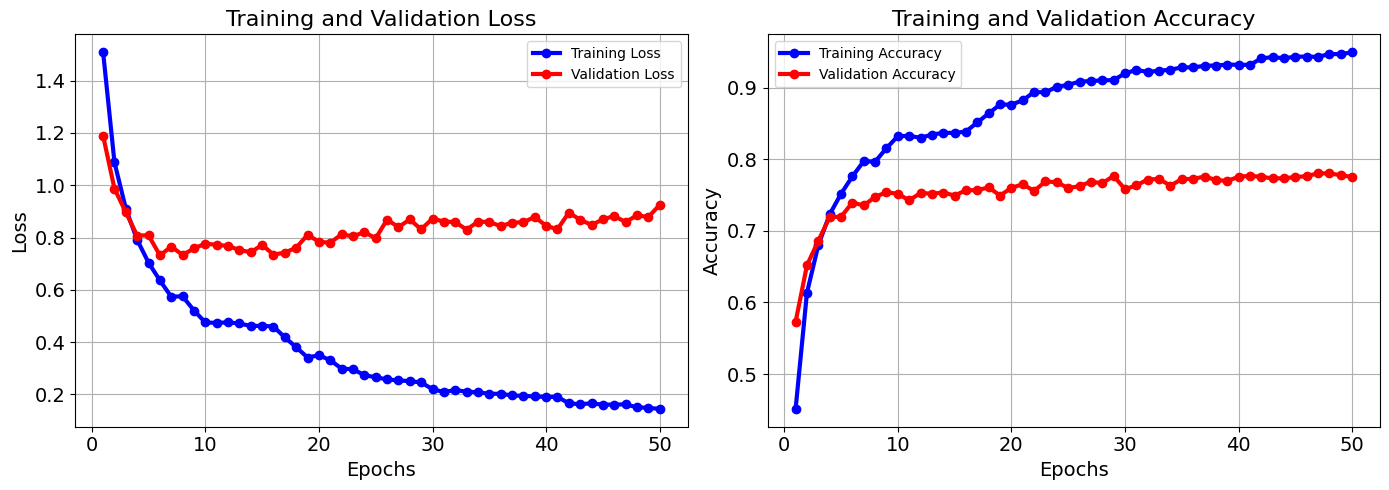

In [27]:
plot_training_history(consine_history)

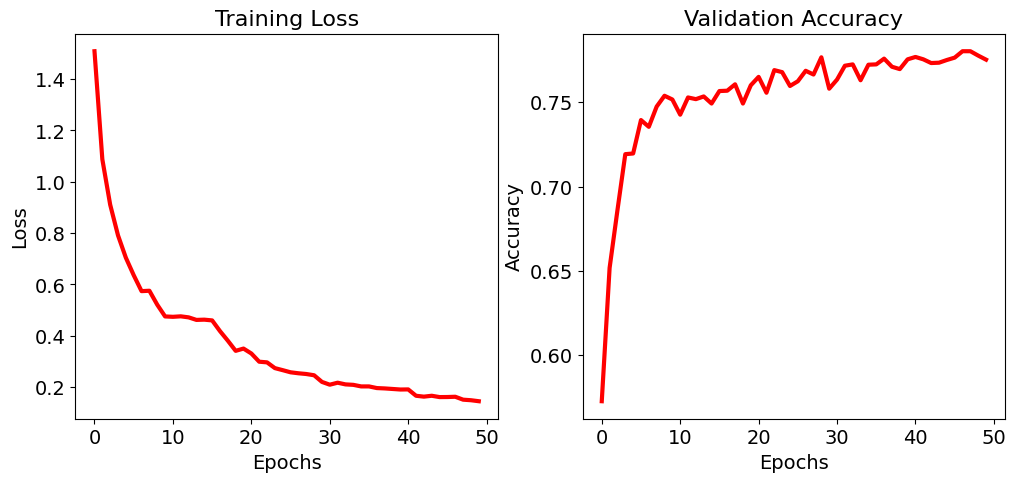

In [28]:
plot_learning(consine_history, "red")

## Final test evaluation

After training, the notebook evaluates the restored model on the separate CIFAR-10 test split with batch size 128 and reports average loss, accuracy, macro precision, macro recall, and macro F1. The recorded output is 77.69% test accuracy, 0.8998 loss, 0.7757 precision, 0.7769 recall, and 0.7759 F1.

**Interpretation caveat:** the earlier Optuna search notebook used the official test split as its evaluation set, so test performance has already influenced hyperparameter selection. The reported score is the notebook’s result, but it is not a fully untouched, unbiased estimate. The in-loop checkpoint restoration issue described above also means this run should be repeated after correcting the checkpoint placement before using the number as a final CV result.

In [34]:
test_data = ds['test']
test_data = CIFAR_10(test_data, TRANSFORM)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)



In [35]:
# avg_loss, acc, prec, recall, f1_score
loss_fcn = nn.CrossEntropyLoss()
avg_loss, test_acc, test_prec, test_recall, test_f1_score = evaluate_epoch(model, test_loader, loss_fcn, device, num_classes=10)

Evaluating:   0%|          | 0/79 [00:00<?, ?it/s]

In [36]:
print(f"Test Average Loss: {avg_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Precision: {test_prec:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1 Score: {test_f1_score:.4f}")

Test Average Loss: 0.8998
Test Accuracy: 0.7769
Test Precision: 0.7757
Test Recall: 0.7769
Test F1 Score: 0.7759


# Conclusion

This notebook applies the best recorded Optuna settings to a fresh three-block CIFAR-10 CNN and trains it with Adam and cosine annealing for 50 epochs. It uses a seeded, stratified 45,000/5,000 training/validation split, selects checkpoints by validation accuracy, visualizes learning curves, and evaluates on the official test split.

The stored outputs show a best validation accuracy of **78.02% at epoch 47** and a test accuracy of **77.69%** (test loss 0.8998; macro precision 0.7757, recall 0.7769, and F1 0.7759). Treat these as preliminary: the earlier Optuna study evaluated candidates on the official test split, and the current checkpoint is restored inside the epoch loop rather than once after training. Move checkpoint restoration after the loop and rerun the final training before reporting these metrics as the project’s final result. Then keep the test set untouched for the final evaluation of the corrected workflow.